# SUNSHIELD — LSTM anomaly detection for solar inverters

**Run:** *Runtime → Run all*. On Colab you are asked to upload the 4 Kaggle CSV files; locally they are read
from `data/raw` or from the notebook's folder. About 30–40 min on a CPU (faster on a GPU runtime).

Parts follow Dr. Mai's workflow: **1** data → **2** LSTM predicted line → **3** anomaly definition →
**4** F1 per k on training → best k → test. **5** compares with the previous method.
The method and its references are explained in the method document.

In [1]:
import os, sys, json, time, shutil
from pathlib import Path
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.width', 160)
IN_COLAB = 'google.colab' in sys.modules

# ---- settings ----------------------------------------------------------------------------------------------
PLANTS = [4135001, 4136001]
GEN = {4135001: 'Plant_1_Generation_Data.csv', 4136001: 'Plant_2_Generation_Data.csv'}
WEA = {4135001: 'Plant_1_Weather_Sensor_Data.csv', 4136001: 'Plant_2_Weather_Sensor_Data.csv'}
CSV_NAMES = [GEN[4135001], WEA[4135001], GEN[4136001], WEA[4136001]]
WEATHER = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']
FEATURES = WEATHER + ['TOD_SIN', 'TOD_COS']           # LSTM inputs: weather + time of day
SPLITS, SPLIT_NAMES = ['train', 'val', 'test'], {'train': 'Training', 'val': 'Validation', 'test': 'Testing'}
MAX_FILL_STEPS = 4            # weather gaps up to 1 hour are interpolated
MIN_PEERS = 5                 # peer reference needs at least 5 other inverters
GAMMA = -0.004                # PV power temperature coefficient (1/°C)
PLANT_EVENT_RATIO = 0.5       # peers below 50 % of the physical expectation -> use the physical formula
FLOOR_FRAC = 0.20             # deviation divided by max(expected, 20 % of capacity)
SEED, N_SEEDS = 42, 3         # 3 networks per plant, averaged
WINDOW_SIZES = [4, 8, 16, 32, 48]
EPOCHS, BATCH_SIZE, LEARNING_RATE, PATIENCE = 400, 64, 1e-3, 30
CLEAN_Z = 3.0                 # training uses healthy readings only (within 3 sigma of the peers)
K_VALUES = [1.0, 1.5, 2.0, 2.5, 3.0]
EWMA_SPAN = 4                 # 1-hour smoothing
MIN_HISTORY = 20              # readings needed before an inverter can be flagged
SIGMA_MIN = 0.10              # sigma never below 10 % of the expected power
RUN_COMPARISON = True         # Part 5 (trains 6 more networks)

OUT = Path('outputs'); RES = OUT / 'results'; FINAL = OUT / 'final_files'
for d in (OUT, RES, FINAL):
    d.mkdir(parents=True, exist_ok=True)

# ---- chart style --------------------------------------------------------------------------------------------
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, AQUA, CRITICAL, BAND = '#2a78d6', '#eb6834', '#1baf7a', '#d03b3b', '#cde2fb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': GRID,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})

## The data files
Upload the 4 CSV files when asked (Colab), or keep them in `data/raw` / next to the notebook.

In [2]:
def locate(name):
    stem = name[:-4]
    for d in (Path('.'), Path('data/raw'), Path('../data/raw'), Path('/content')):
        if (d / name).exists():
            return d / name
        hits = sorted(d.glob(stem + '*.csv')) if d.exists() else []   # e.g. "Plant_1_Generation_Data (1).csv"
        if hits:
            return hits[0]
    return None

missing = [n for n in CSV_NAMES if locate(n) is None]
if missing and IN_COLAB:
    from google.colab import files
    print('Choose the 4 CSV files:', ', '.join(CSV_NAMES))
    files.upload()
    missing = [n for n in CSV_NAMES if locate(n) is None]
if missing:
    raise FileNotFoundError(f'Missing data files: {missing}. Put them next to this notebook or in data/raw.')
PATHS = {n: locate(n) for n in CSV_NAMES}
for n, p in PATHS.items():
    print(f'{n:35s} ← {p}')

Plant_1_Generation_Data.csv         ← ../data/raw/Plant_1_Generation_Data.csv
Plant_1_Weather_Sensor_Data.csv     ← ../data/raw/Plant_1_Weather_Sensor_Data.csv
Plant_2_Generation_Data.csv         ← ../data/raw/Plant_2_Generation_Data.csv
Plant_2_Weather_Sensor_Data.csv     ← ../data/raw/Plant_2_Weather_Sensor_Data.csv


# Part 1 — Preprocessing and data split
Weather on a continuous 15-min timeline (gaps ≤ 1 h filled), night removed, split 70/15/15 by whole days.
Expected power of a healthy inverter = **median of the other inverters** at the same moment
(physical PV formula when the whole plant is down). This reference gives the **Actual 0/1**.

In [3]:
def read_csv(name):
    df = pd.read_csv(PATHS[name])
    fmt = '%d-%m-%Y %H:%M' if name == GEN[4135001] else '%Y-%m-%d %H:%M:%S'
    try:
        df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'], format=fmt)
    except ValueError:
        df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'], dayfirst=(name == GEN[4135001]))
    return df

gen = pd.concat([read_csv(GEN[p]) for p in PLANTS], ignore_index=True)
wea = pd.concat([read_csv(WEA[p]) for p in PLANTS], ignore_index=True)

def fill_short_gaps(s, max_steps=MAX_FILL_STEPS):
    na = s.isna()
    run_len = na.groupby((na != na.shift()).cumsum()).transform('sum')
    return s.where(~(na & (run_len <= max_steps)), s.interpolate(limit_area='inside'))

parts = []
for plant, w in wea.groupby('PLANT_ID'):
    grid = pd.date_range(w.DATE_TIME.min().normalize(), w.DATE_TIME.max().normalize() + pd.Timedelta('1D') - pd.Timedelta('15min'),
                         freq='15min', name='DATE_TIME')
    g = w.set_index('DATE_TIME')[WEATHER].reindex(grid)
    for c in WEATHER:
        g[c] = fill_short_gaps(g[c])
    parts.append(g.reset_index().assign(PLANT_ID=plant))
weather = pd.concat(parts, ignore_index=True)
minutes = weather.DATE_TIME.dt.hour * 60 + weather.DATE_TIME.dt.minute
weather['TOD_SIN'], weather['TOD_COS'] = np.sin(2 * np.pi * minutes / 1440), np.cos(2 * np.pi * minutes / 1440)

def split_by_days(dates):
    days = np.sort(dates.dt.normalize().unique())
    n_tr, n_va = round(len(days) * 0.70), round(len(days) * 0.15)
    label = pd.Series(['train'] * n_tr + ['val'] * n_va + ['test'] * (len(days) - n_tr - n_va), index=days)
    return dates.dt.normalize().map(label)

df = gen[['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AC_POWER']].merge(weather[['PLANT_ID', 'DATE_TIME'] + WEATHER],
                                                                    on=['PLANT_ID', 'DATE_TIME'], how='left')
df = df.dropna(subset=WEATHER)
df = df[df.IRRADIATION > 0].copy()                      # night removed; 0 kW in daylight is kept (faults)
df['SPLIT'] = split_by_days(df.DATE_TIME)
weather['SPLIT'] = split_by_days(weather.DATE_TIME)

def loo_median(values):
    """Median of the OTHER inverters at the same moment (the inverter itself left out)."""
    v = np.asarray(values, float)
    if len(v) - 1 < MIN_PEERS:
        return np.full(len(v), np.nan)
    return np.array([np.median(np.delete(v, i)) for i in range(len(v))])

df['PEER_MEDIAN_kW'] = df.groupby(['PLANT_ID', 'DATE_TIME'])['AC_POWER'].transform(loo_median)
phys_unit = df.IRRADIATION * (1 + GAMMA * (df.MODULE_TEMPERATURE - 25))
train_sunny = (df.SPLIT == 'train') & (df.IRRADIATION > 0.2) & df.PEER_MEDIAN_kW.notna()
CAPACITY = df[df.SPLIT == 'train'].groupby('PLANT_ID').AC_POWER.quantile(0.999).to_dict()
PHYS_A = (df.PEER_MEDIAN_kW / phys_unit)[train_sunny].groupby(df.PLANT_ID).median().to_dict()
df['CAPACITY_kW'] = df.PLANT_ID.map(CAPACITY)
df['FLOOR_kW'] = FLOOR_FRAC * df.CAPACITY_kW
df['EXPECTED_PHYS_kW'] = phys_unit * df.PLANT_ID.map(PHYS_A)
df['PLANT_EVENT'] = (df.PEER_MEDIAN_kW < PLANT_EVENT_RATIO * df.EXPECTED_PHYS_kW) & (df.EXPECTED_PHYS_kW > df.FLOOR_kW)
df['EXPECTED_PEER_kW'] = np.where(df.PLANT_EVENT, df.EXPECTED_PHYS_kW, df.PEER_MEDIAN_kW)
df = df.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)

print(f'{len(gen):,} generation rows → {len(df):,} daylight readings | 0 kW in daylight: {(df.AC_POWER == 0).sum():,}')
print('capacity (kW):', {p: round(v) for p, v in CAPACITY.items()}, '| physical formula a:', {p: round(v) for p, v in PHYS_A.items()})
split_table = (df.groupby('SPLIT').agg(first=('DATE_TIME', 'min'), last=('DATE_TIME', 'max'),
                                       days=('DATE_TIME', lambda s: s.dt.normalize().nunique()), readings=('AC_POWER', 'size'))
               .loc[SPLITS].assign(share=lambda t: (100 * t.readings / t.readings.sum()).round(1)))
split_table

136,476 generation rows → 77,102 daylight readings | 0 kW in daylight: 8,253
capacity (kW): {4135001: 1346, 4136001: 1343} | physical formula a: {4135001: 1472, 4136001: 1458}


,first,last,days,readings,share
SPLIT,,,,,
train,2020-05-15 05:45:00,2020-06-07 19:00:00,24,53342,69.2
val,2020-06-08 05:45:00,2020-06-12 18:45:00,5,11968,15.5
test,2020-06-13 05:45:00,2020-06-17 18:45:00,5,11792,15.3


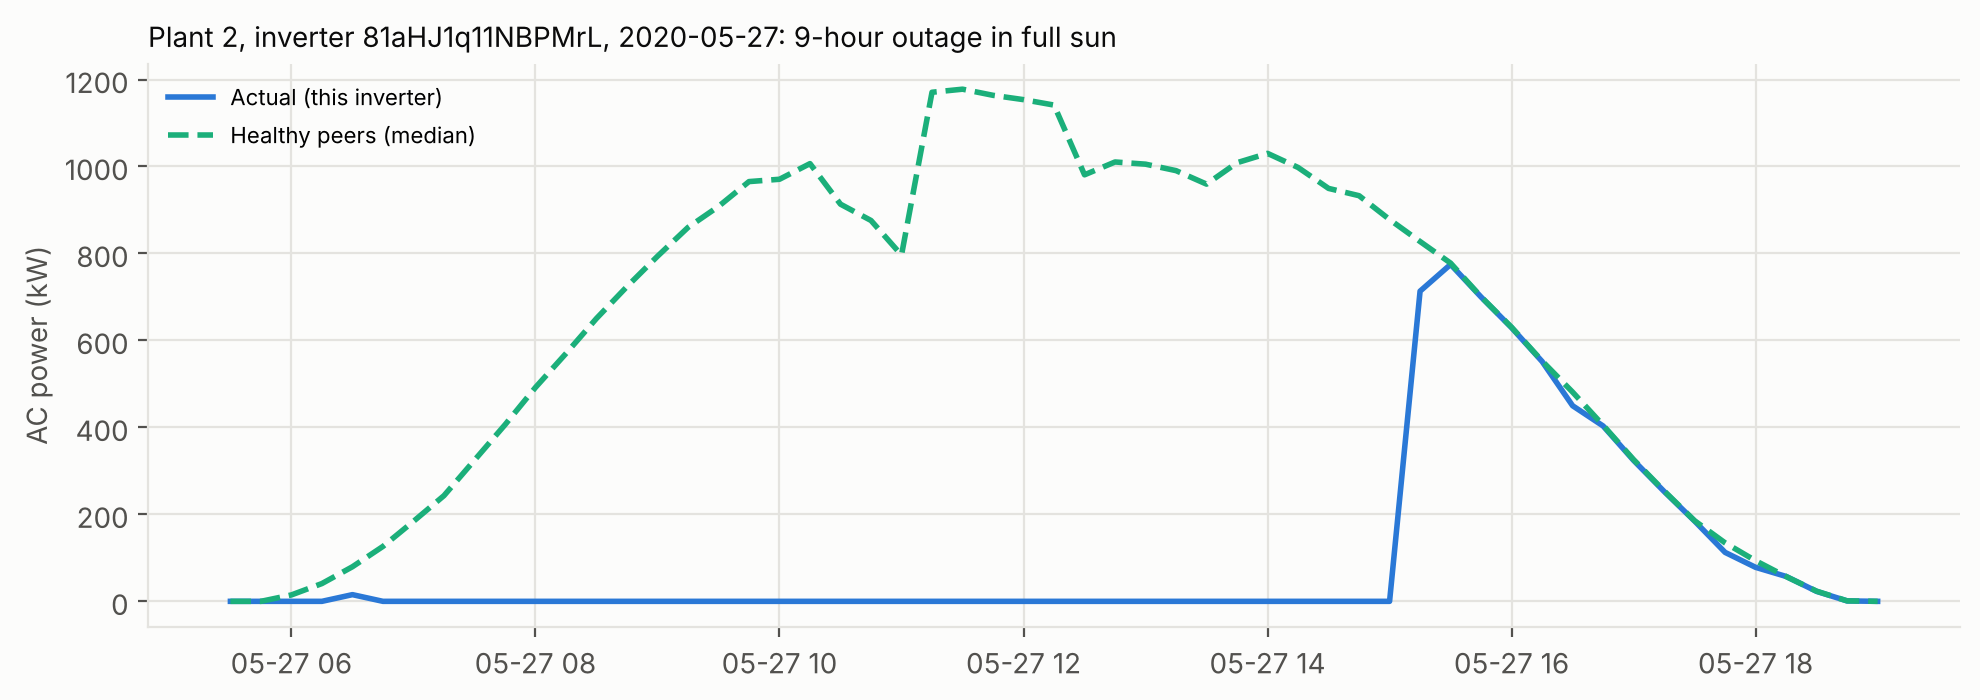

In [4]:
def plot_day(ax, g, title, flag_col=None):
    ax.plot(g.DATE_TIME, g.AC_POWER, color=BLUE, label='Actual (this inverter)')
    ax.plot(g.DATE_TIME, g.EXPECTED_PEER_kW, color=AQUA, linestyle='--', label='Healthy peers (median)')
    if 'EXPECTED_LSTM_kW' in g:
        ax.plot(g.DATE_TIME, g.EXPECTED_LSTM_kW, color=ORANGE, label='LSTM expected')
    if flag_col:
        f = g[g[flag_col] != 0]
        ax.plot(f.DATE_TIME, f.AC_POWER, 'o', color=CRITICAL, markersize=6, markeredgecolor=SURFACE, label='Anomaly')
    ax.set_ylabel('AC power (kW)'); ax.set_title(title, fontsize=10); ax.legend(loc='upper left', fontsize=8)

OUTAGE_INV, OUTAGE_DAY = '81aHJ1q11NBPMrL', '2020-05-27'
example = df[(df.SOURCE_KEY == OUTAGE_INV) & (df.DATE_TIME.dt.date == pd.Timestamp(OUTAGE_DAY).date())]
fig, ax = plt.subplots(figsize=(10, 3.6))
plot_day(ax, example, f'Plant 2, inverter {OUTAGE_INV}, {OUTAGE_DAY}: 9-hour outage in full sun')
fig.tight_layout(); plt.show()

# Part 2 — LSTM (predicted line)
The LSTM learns the power of a **healthy** inverter from the last 2 hours of weather and time of day.
Training uses healthy readings only: a reading more than 3σ away from the peers is left out of training.

In [5]:
import tensorflow as tf
import keras
from keras import layers
tf.get_logger().setLevel('ERROR')
if not tf.config.list_physical_devices('GPU'):
    tf.config.experimental.enable_op_determinism()

def relative_deviation(actual, expected, floor):
    actual, expected, floor = (np.asarray(v, float) for v in (actual, expected, floor))
    return (actual - expected) / np.maximum(expected, floor)

# healthy readings → training target = mean power of the healthy inverters at each moment
dev = pd.Series(relative_deviation(df.AC_POWER, df.EXPECTED_PEER_kW, df.FLOOR_kW), index=df.index)
tr = dev[df.SPLIT == 'train'].groupby(df.SOURCE_KEY)
centre = tr.median()
sigma = (1.4826 * tr.apply(lambda s: np.median(np.abs(s - s.median())))).clip(lower=SIGMA_MIN)
df['HEALTHY'] = (((dev - df.SOURCE_KEY.map(centre)) / df.SOURCE_KEY.map(sigma)).abs() <= CLEAN_Z) & ~df.PLANT_EVENT
targets = (df[df.HEALTHY].groupby(['PLANT_ID', 'DATE_TIME', 'SPLIT']).AC_POWER
           .agg(TARGET_kW='mean', N='size').reset_index())
zero_in_sun = (df.AC_POWER == 0) & (df.IRRADIATION > 0.2)
print(f'healthy readings: {df.HEALTHY.mean():.1%} | 0 kW in sun (> 0.2 kW/m²): {zero_in_sun.sum():,}, '
      f'used in training: {(zero_in_sun & df.HEALTHY).sum()}')

# inputs standardised with training statistics, on the continuous timeline (night included)
timeline = {}
for plant, g in weather.groupby('PLANT_ID'):
    g = g.sort_values('DATE_TIME').reset_index(drop=True)
    X = g[FEATURES].to_numpy(np.float32).copy()
    t = g[g.SPLIT == 'train']
    for j, c in enumerate(WEATHER):
        X[:, j] = (X[:, j] - t[c].mean()) / t[c].std()
    timeline[plant] = (g.DATE_TIME.to_numpy(), X)

def windows(plant, timestamps, W):
    """X[i] = the W weather readings ending at timestamps[i]; a window with a long weather gap is dropped."""
    times, feats = timeline[plant]
    pos = pd.Index(times).get_indexer(pd.to_datetime(timestamps))
    valid = pos >= W - 1
    X = feats[pos[valid][:, None] + np.arange(-W + 1, 1)[None, :]]
    ok = ~np.isnan(X).any(axis=(1, 2))
    valid[np.flatnonzero(valid)[~ok]] = False
    return X[ok], valid

def plant_data(tgt, plant, W):
    out = {}
    for s in SPLITS:
        t = tgt[(tgt.PLANT_ID == plant) & (tgt.SPLIT == s)]
        X, valid = windows(plant, t.DATE_TIME, W)
        t = t[valid]
        out[s] = (X, (t.TARGET_kW / CAPACITY[plant]).to_numpy(np.float32), t.N.to_numpy(np.float32))
    return out

def build_lstm(W):
    m = keras.Sequential([keras.Input(shape=(W, len(FEATURES))),
                          layers.LSTM(64, return_sequences=True), layers.Dropout(0.2),
                          layers.LSTM(32), layers.Dropout(0.2),
                          layers.Dense(16, activation='relu'), layers.Dense(1, activation='softplus')])
    m.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss='mse')
    return m

def train(data, W, seed):
    keras.utils.set_random_seed(seed)
    m = build_lstm(W)
    (Xtr, ytr, wtr), (Xva, yva, wva) = data['train'], data['val']
    h = m.fit(Xtr, ytr, sample_weight=wtr, validation_data=(Xva, yva, wva), epochs=EPOCHS, batch_size=BATCH_SIZE,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)], verbose=0)
    return m, h.history

def predict(models, W):
    out = pd.Series(np.nan, index=df.index)
    for plant, g in df.groupby('PLANT_ID'):
        keys = g[['DATE_TIME']].drop_duplicates()
        X, valid = windows(plant, keys.DATE_TIME, W)
        pred = np.mean([m.predict(X, batch_size=4096, verbose=0).ravel() for m in models[plant]], axis=0)
        keys = keys[valid].assign(P=pred * CAPACITY[plant])
        out.loc[g.index] = g[['DATE_TIME']].merge(keys, on='DATE_TIME', how='left').P.to_numpy()
    return out

healthy readings: 83.8% | 0 kW in sun (> 0.2 kW/m²): 3,821, used in training: 0


### Window size (chosen by validation loss)

In [6]:
rows, first = [], {}
for W in WINDOW_SIZES:
    for plant in PLANTS:
        start = time.time()
        m, h = train(plant_data(targets, plant, W), W, SEED)
        first[(W, plant)] = (m, h)
        rows.append({'window': W, 'hours': W / 4, 'plant': plant, 'val loss': min(h['val_loss']),
                     'epochs': len(h['val_loss']), 'minutes': round((time.time() - start) / 60, 1)})
window_table = pd.DataFrame(rows)
mean_loss = window_table.groupby('window')['val loss'].mean()
BEST_W = int(mean_loss.idxmin())
print(f'chosen window: {BEST_W} readings = {BEST_W / 4:g} hours')
mean_loss.round(5).to_frame('mean validation loss (2 plants)')

chosen window: 8 readings = 2 hours


,mean validation loss (2 plants)
window,
4,0.01714
8,0.01627
16,0.01890
32,0.01668
48,0.01739


### Final models: 3 seeds per plant, averaged

In [7]:
models = {}
for plant in PLANTS:
    data = plant_data(targets, plant, BEST_W)
    models[plant] = [first[(BEST_W, plant)][0]] + [train(data, BEST_W, SEED + s)[0] for s in range(1, N_SEEDS)]
    for s, m in enumerate(models[plant]):
        m.save(OUT / f'lstm_plant_{plant}_seed{SEED + s}.keras')
df['EXPECTED_LSTM_kW'] = predict(models, BEST_W)

def errors(g):
    e, eh = (g.AC_POWER - g.EXPECTED_LSTM_kW).dropna(), (g.AC_POWER - g.EXPECTED_LSTM_kW)[g.HEALTHY].dropna()
    return pd.Series({'RMSE healthy (kW)': np.sqrt((eh ** 2).mean()), 'MAE healthy (kW)': eh.abs().mean(),
                      'RMSE all (kW)': np.sqrt((e ** 2).mean())})
lstm_errors = df.groupby(['PLANT_ID', 'SPLIT']).apply(errors, include_groups=False).round(1)
print('readings without a prediction (weather gap):', int(df.EXPECTED_LSTM_kW.isna().sum()))
lstm_errors

readings without a prediction (weather gap): 594


RMSE healthy (kW)  MAE healthy (kW)  RMSE all (kW)
PLANT_ID SPLIT                                                    
4135001  test                44.4              29.8           78.0
         train               55.3              35.3           73.2
         val                 45.9              29.8           46.8
4136001  test                45.2              29.9          273.5
         train               56.6              32.7          360.3
         val                 58.7              31.9          296.8

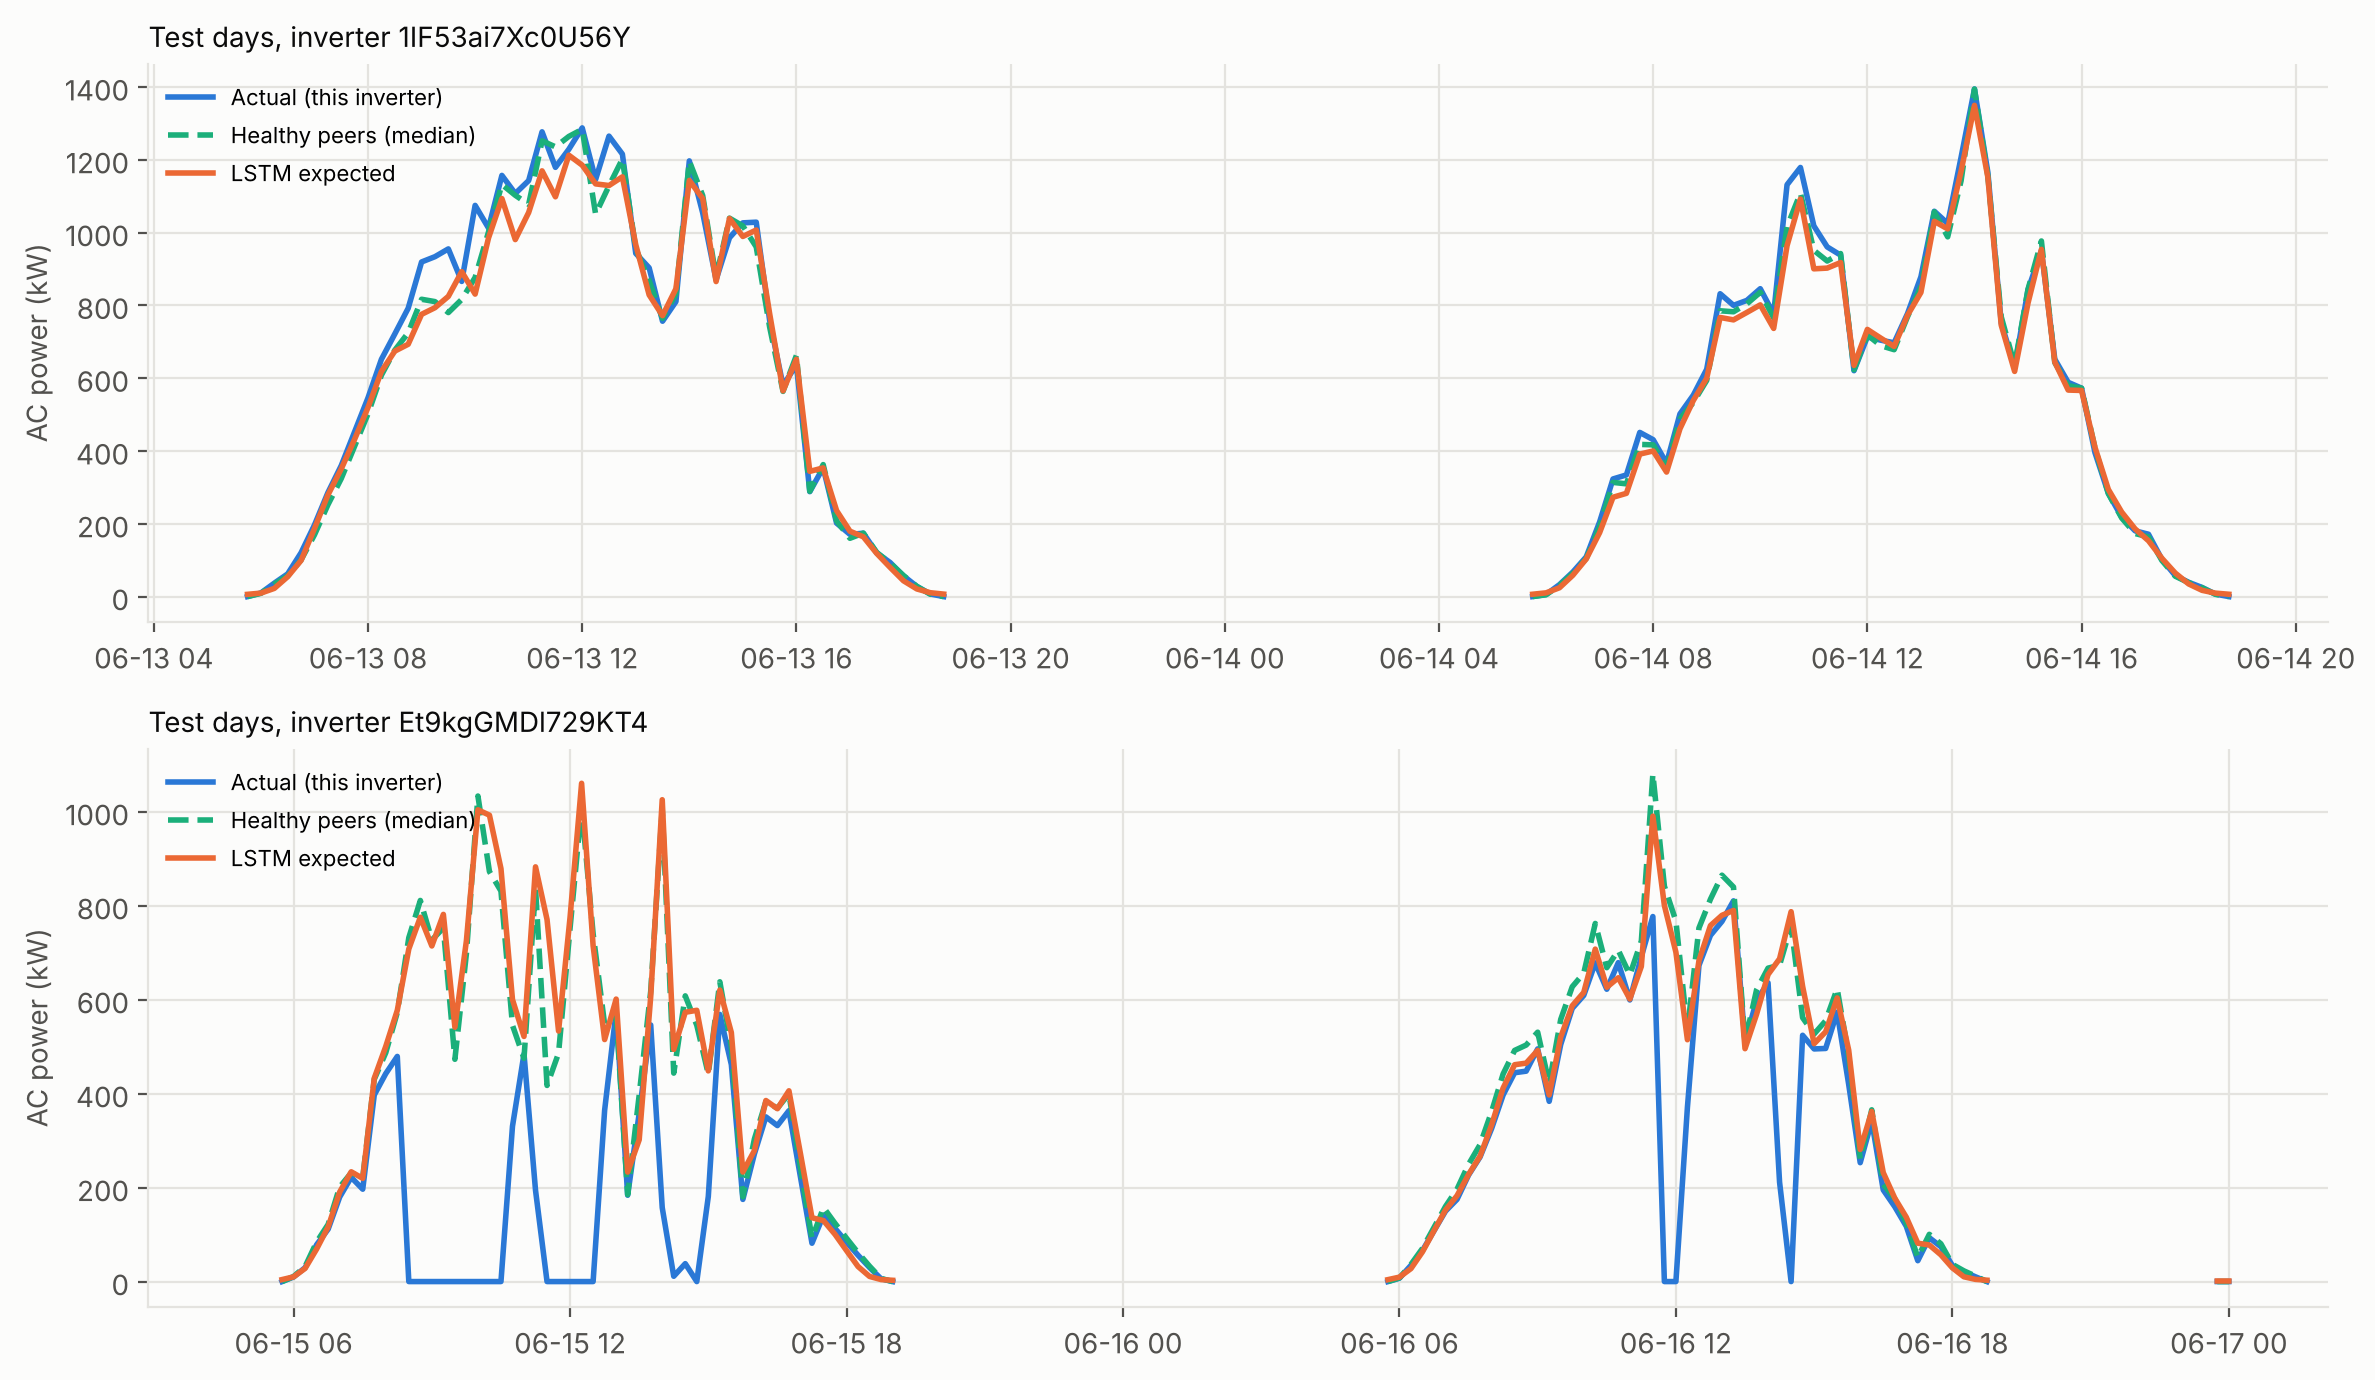

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (inv, d0) in zip(axes, [('1IF53ai7Xc0U56Y', '2020-06-13'), ('Et9kgGMDl729KT4', '2020-06-15')]):
    g = df[(df.SOURCE_KEY == inv) & df.DATE_TIME.between(d0, pd.Timestamp(d0) + pd.Timedelta('2D'))]
    g = g.set_index('DATE_TIME').asfreq('15min').reset_index()
    plot_day(ax, g, f'Test days, inverter {inv}')
fig.tight_layout(); plt.show()

# Part 3 — Anomaly definition (k = 1, 1.5, 2, 2.5, 3; each line alone)
deviation = (actual − expected) / max(expected, 20 % capacity) → 1-hour EWMA → expanding median ± k·σ
from reading 0 to t, with σ = max(1.4826·MAD, 10 %). Rise = +1, drop = −1.
Expected = healthy peers → **Actual 0/1**; expected = LSTM → **Predicted 0/1**.

In [9]:
def ewma(x, span=EWMA_SPAN):
    if span <= 1:
        return np.asarray(x, float)
    return pd.Series(np.asarray(x, float)).ewm(span=span, adjust=False, ignore_na=True).mean().to_numpy()

def expanding_median_mad(x, min_history=MIN_HISTORY):
    """centre = median and sigma = 1.4826·MAD of x[0..t] (the reading and everything before it)."""
    centre, sig, hist = np.full(len(x), np.nan), np.full(len(x), np.nan), []
    for t, v in enumerate(x):
        if np.isnan(v):
            continue
        hist.append(v)
        if len(hist) >= min_history:
            h = np.asarray(hist); med = np.median(h)
            centre[t], sig[t] = med, 1.4826 * np.median(np.abs(h - med))
    return centre, sig

def expanding_mean_std(x, min_history=MIN_HISTORY):
    s = pd.Series(np.asarray(x, float)); n = s.notna().cumsum()
    return s.expanding().mean().where(n >= min_history).to_numpy(), s.expanding().std(ddof=0).where(n >= min_history).to_numpy()

def flags(x, centre, sig, k, sigma_min=SIGMA_MIN):
    sig = np.maximum(np.nan_to_num(sig, nan=0.0), max(sigma_min, 1e-9))
    out = np.zeros(len(x), int); ok = ~np.isnan(x) & ~np.isnan(centre)
    out[ok & (x > centre + k * sig)] = 1
    out[ok & (x < centre - k * sig)] = -1
    return out

def flag_line(data, col, prefix, span=EWMA_SPAN, sigma_min=SIGMA_MIN, robust=True):
    """The definition on one deviation line, per inverter, in time order; adds <prefix>_k<k> columns (+1/-1/0)."""
    stats = expanding_median_mad if robust else expanding_mean_std
    raw = data[col].to_numpy(float)
    sm, c, s = (np.full(len(data), np.nan) for _ in range(3))
    for idx in data.groupby('SOURCE_KEY', sort=False).indices.values():
        sm[idx] = ewma(raw[idx], span)
        c[idx], s[idx] = stats(sm[idx])
    out = pd.DataFrame({f'{prefix}_smooth': sm, f'{prefix}_centre': c,
                        f'{prefix}_sigma': np.where(np.isnan(s), np.nan, np.maximum(s, sigma_min))}, index=data.index)
    for k in K_VALUES:
        out[f'{prefix}_k{k:g}'] = flags(sm, c, s, k, sigma_min)
    return out

# small test: rise, drop and a 30-reading outage are found; a later 45 % drop is found by median/MAD, missed by mean/std
x = np.random.default_rng(0).normal(0, 0.03, 200); x[60], x[90], x[120:150], x[170] = 0.5, -0.5, -1.0, -0.45
c, s = expanding_median_mad(x); f = flags(x, c, s, 3)
m_, s_ = expanding_mean_std(x)
assert f[60] == 1 and f[90] == -1 and (f[120:150] == -1).all() and f[170] == -1 and flags(x, m_, s_, 3)[170] == 0
print('test passed: rise, drop, outage and later drop found; mean ± 3·std misses the later drop')

test passed: rise, drop, outage and later drop found; mean ± 3·std misses the later drop


In [10]:
df['DEV_PEER'] = relative_deviation(df.AC_POWER, df.EXPECTED_PEER_kW, df.FLOOR_kW)
df['DEV_LSTM'] = relative_deviation(df.AC_POWER, df.EXPECTED_LSTM_kW, df.FLOOR_kW)
df = df.join(flag_line(df, 'DEV_PEER', 'actual')).join(flag_line(df, 'DEV_LSTM', 'pred'))
pd.DataFrame([{'split': SPLIT_NAMES[s], 'k': k,
               'Actual anomalies': int((df[df.SPLIT == s][f'actual_k{k:g}'] != 0).sum()),
               'Predicted anomalies': int((df[df.SPLIT == s][f'pred_k{k:g}'] != 0).sum())}
              for s in SPLITS for k in K_VALUES]).pivot(index='k', columns='split')

Actual anomalies                     Predicted anomalies                    
split          Testing Training Validation             Testing Training Validation
k                                                                                 
1.0               1296     6289       1226                1406     6549       1410
1.5               1020     4818        938                1001     4758        947
2.0                917     4250        800                 905     4203        840
2.5                825     3942        739                 819     3968        773
3.0                758     3720        680                 759     3712        719

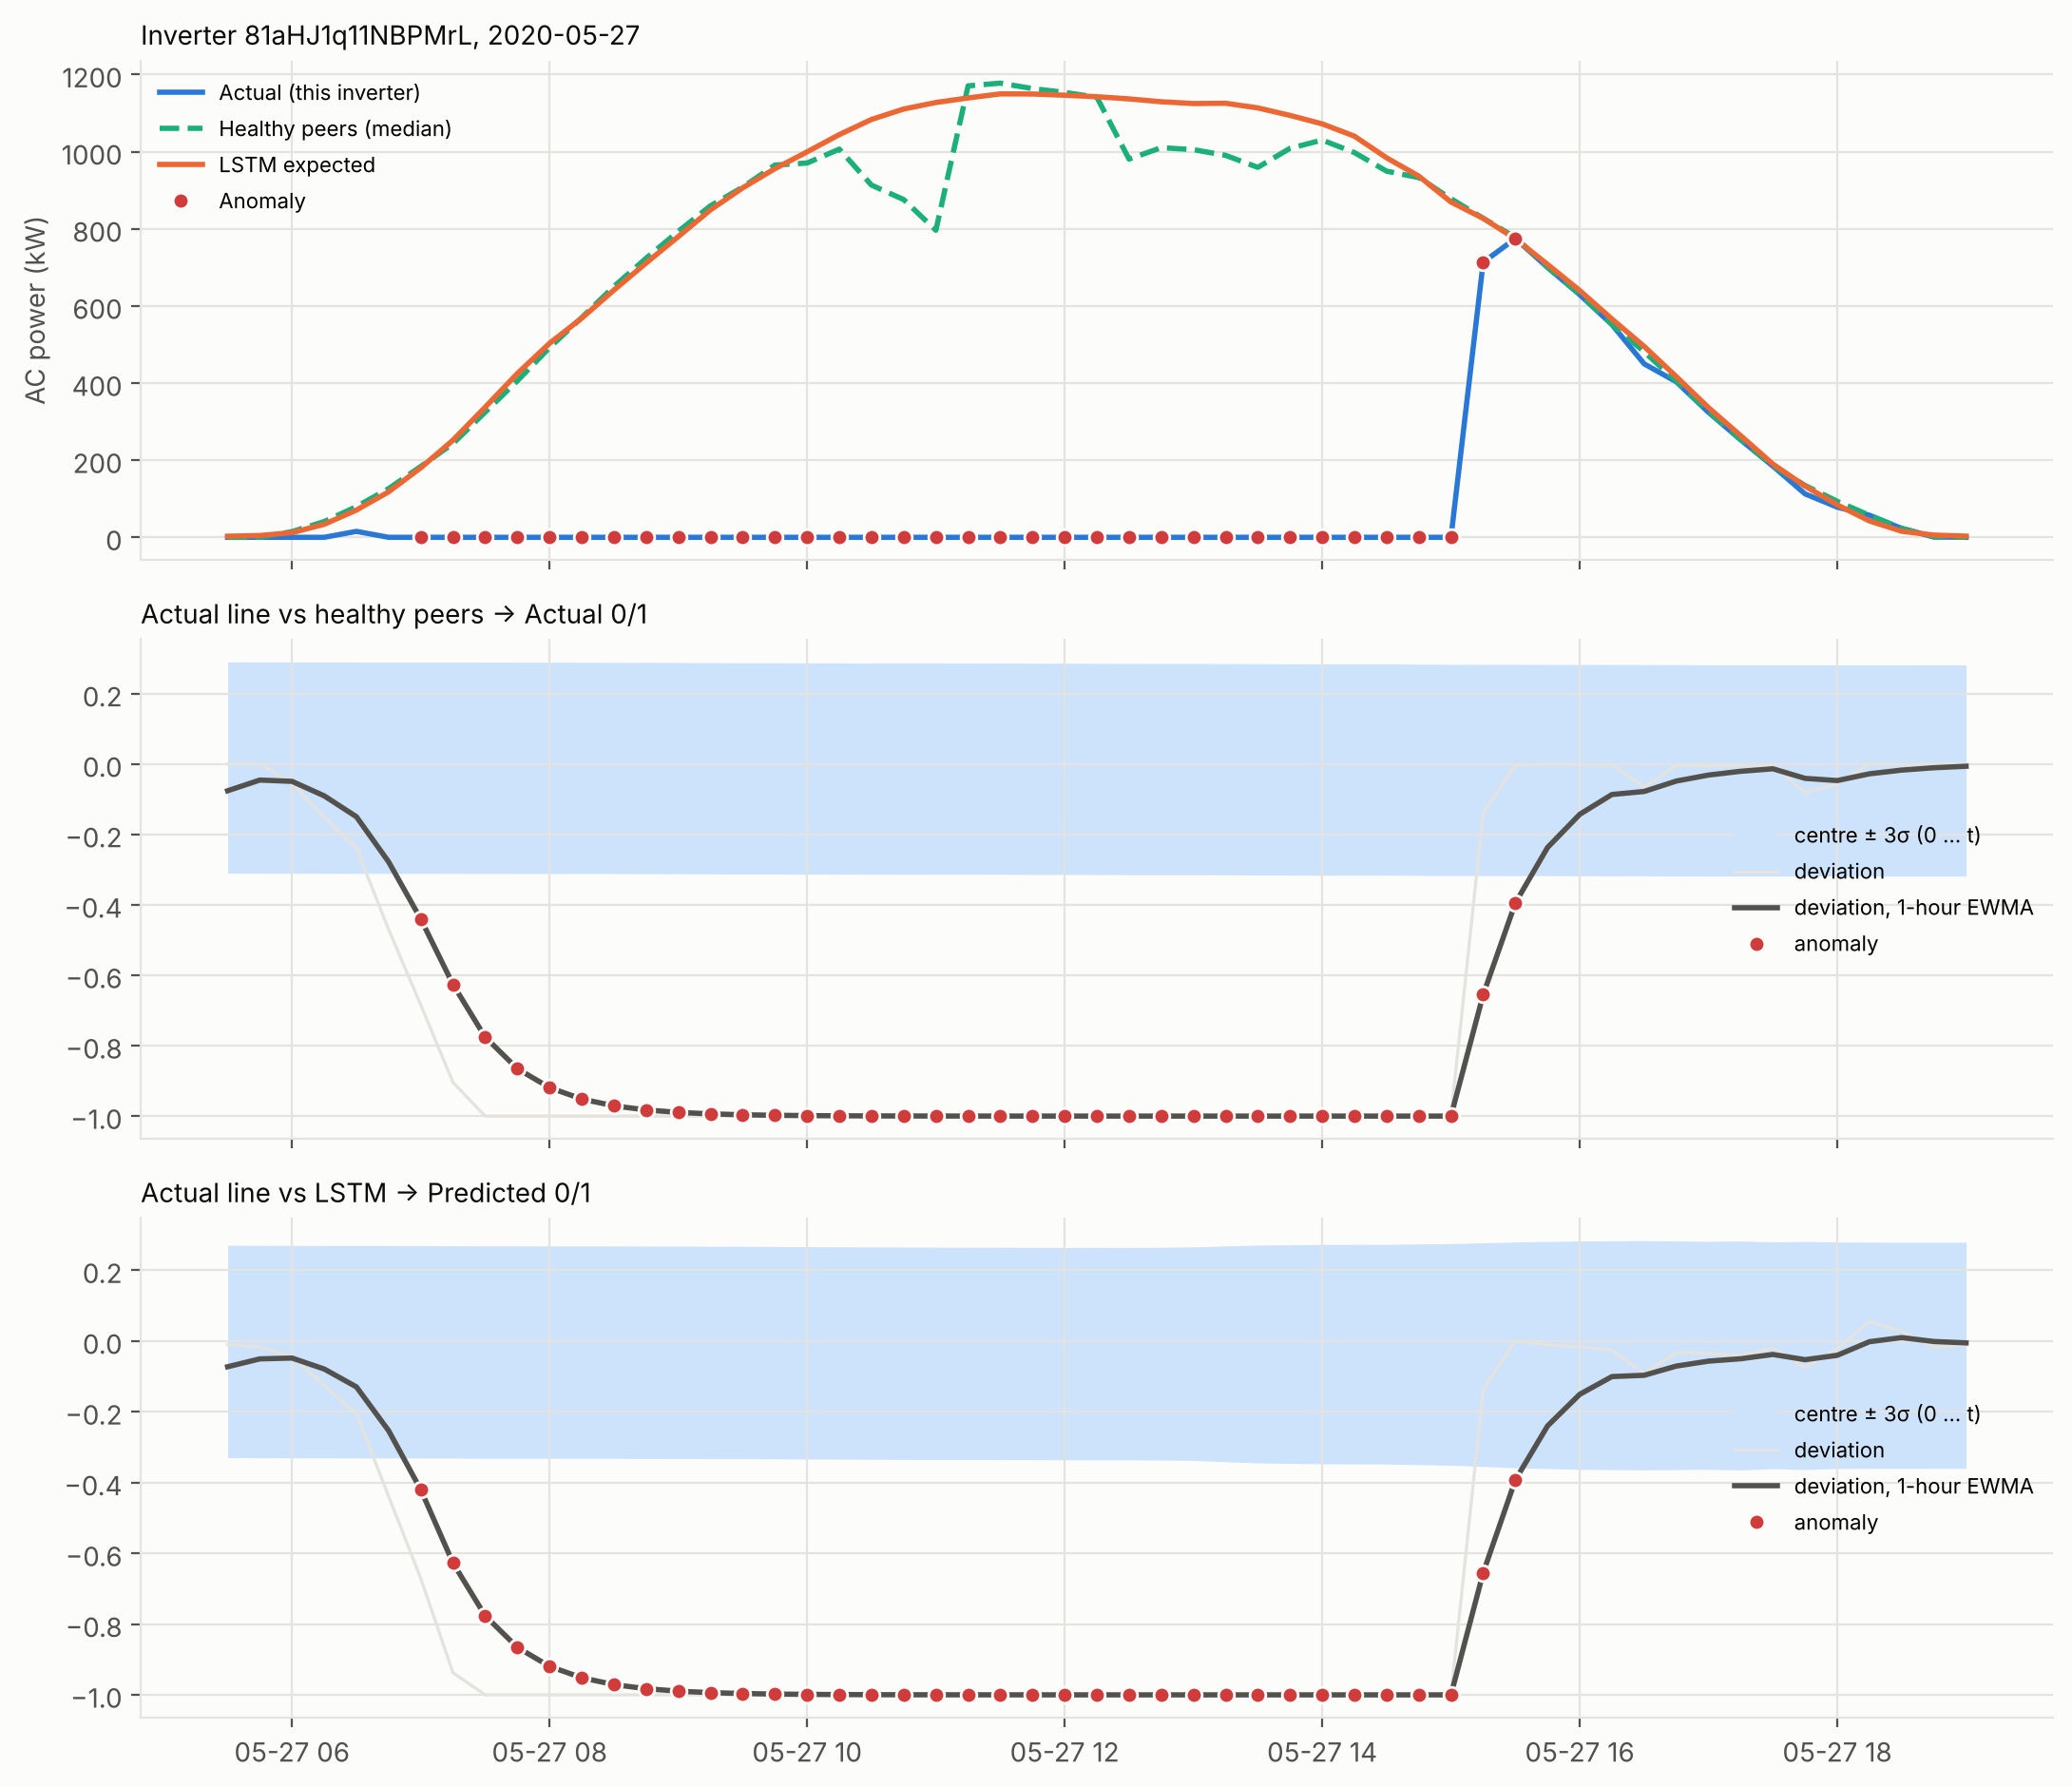

In [11]:
day = df[(df.SOURCE_KEY == OUTAGE_INV) & (df.DATE_TIME.dt.date == pd.Timestamp(OUTAGE_DAY).date())]
fig, axes = plt.subplots(3, 1, figsize=(11, 9.5), sharex=True)
plot_day(axes[0], day, f'Inverter {OUTAGE_INV}, {OUTAGE_DAY}', flag_col='actual_k3')
for ax, line, raw, name in [(axes[1], 'actual', 'DEV_PEER', 'vs healthy peers → Actual 0/1'),
                            (axes[2], 'pred', 'DEV_LSTM', 'vs LSTM → Predicted 0/1')]:
    ax.fill_between(day.DATE_TIME, day[f'{line}_centre'] - 3 * day[f'{line}_sigma'],
                    day[f'{line}_centre'] + 3 * day[f'{line}_sigma'], color=BAND, linewidth=0, label='centre ± 3σ (0 … t)')
    ax.plot(day.DATE_TIME, day[raw], color=GRID, linewidth=1.2, label='deviation')
    ax.plot(day.DATE_TIME, day[f'{line}_smooth'], color=INK_2, label='deviation, 1-hour EWMA')
    fl = day[day[f'{line}_k3'] != 0]
    ax.plot(fl.DATE_TIME, fl[f'{line}_smooth'], 'o', color=CRITICAL, markersize=6, markeredgecolor=SURFACE, label='anomaly')
    ax.set_title(f'Actual line {name}', fontsize=10); ax.legend(loc='center right', fontsize=8)
fig.tight_layout(); fig.savefig(RES / 'definition_example_outage.png', dpi=150); plt.show()

# Part 4 — Evaluation: F1 per k on training → best k → test

In [12]:
def scores(actual, predicted):
    a, p = np.asarray(actual) != 0, np.asarray(predicted) != 0
    tp, fp, fn, tn = int((a & p).sum()), int((~a & p).sum()), int((a & ~p).sum()), int((~a & ~p).sum())
    pr = tp / (tp + fp) if tp + fp else 0.0
    rc = tp / (tp + fn) if tp + fn else 0.0
    return {'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn, 'Precision': round(pr, 4), 'Recall': round(rc, 4),
            'F1': round(2 * pr * rc / (pr + rc), 4) if pr + rc else 0.0}

def sweep(data, a_prefix, p_prefix, by=None):
    groups = [('All', data)] if by is None else list(data.groupby(by))
    return pd.DataFrame([{**({by: name} if by else {}), 'Split': SPLIT_NAMES[s], 'k': k,
                          **scores(g[g.SPLIT == s][f'{a_prefix}_k{k:g}'], g[g.SPLIT == s][f'{p_prefix}_k{k:g}'])}
                         for name, g in groups for s in SPLITS for k in K_VALUES])

def best_k(table):
    t = table[table.Split == 'Training'].sort_values(['F1', 'k'], ascending=[False, True])
    return float(t.iloc[0].k)

def plot_cm(ax, a, p, title):
    a, p = (np.asarray(a) != 0).astype(int), (np.asarray(p) != 0).astype(int)
    cm = np.array([[((a == i) & (p == j)).sum() for j in (0, 1)] for i in (0, 1)])
    ax.imshow(cm, cmap='Blues'); ax.grid(False)
    for i in (0, 1):
        for j in (0, 1):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ['Normal (0)', 'Anomaly (1)']); ax.set_yticks([0, 1], ['Normal (0)', 'Anomaly (1)'])
    ax.set_xlabel('Predicted (LSTM)'); ax.set_ylabel('Actual (peers)'); ax.set_title(title, fontsize=10)

table = sweep(df, 'actual', 'pred')
BEST_K = best_k(table)
table.to_csv(RES / 'f1_all_k.csv', index=False)
print(f'best k (highest training F1) = {BEST_K:g}')
table[table.Split == 'Training']

best k (highest training F1) = 3


,Split,k,TP,FP,FN,TN,Precision,Recall,F1
0,Training,1.0,5255,1294,1034,45759,0.8024,0.8356,0.8187
1,Training,1.5,4359,399,459,48125,0.9161,0.9047,0.9104
2,Training,2.0,4024,179,226,48913,0.9574,0.9468,0.9521
3,Training,2.5,3811,157,131,49243,0.9604,0.9668,0.9636
4,Training,3.0,3588,124,132,49498,0.9666,0.9645,0.9656


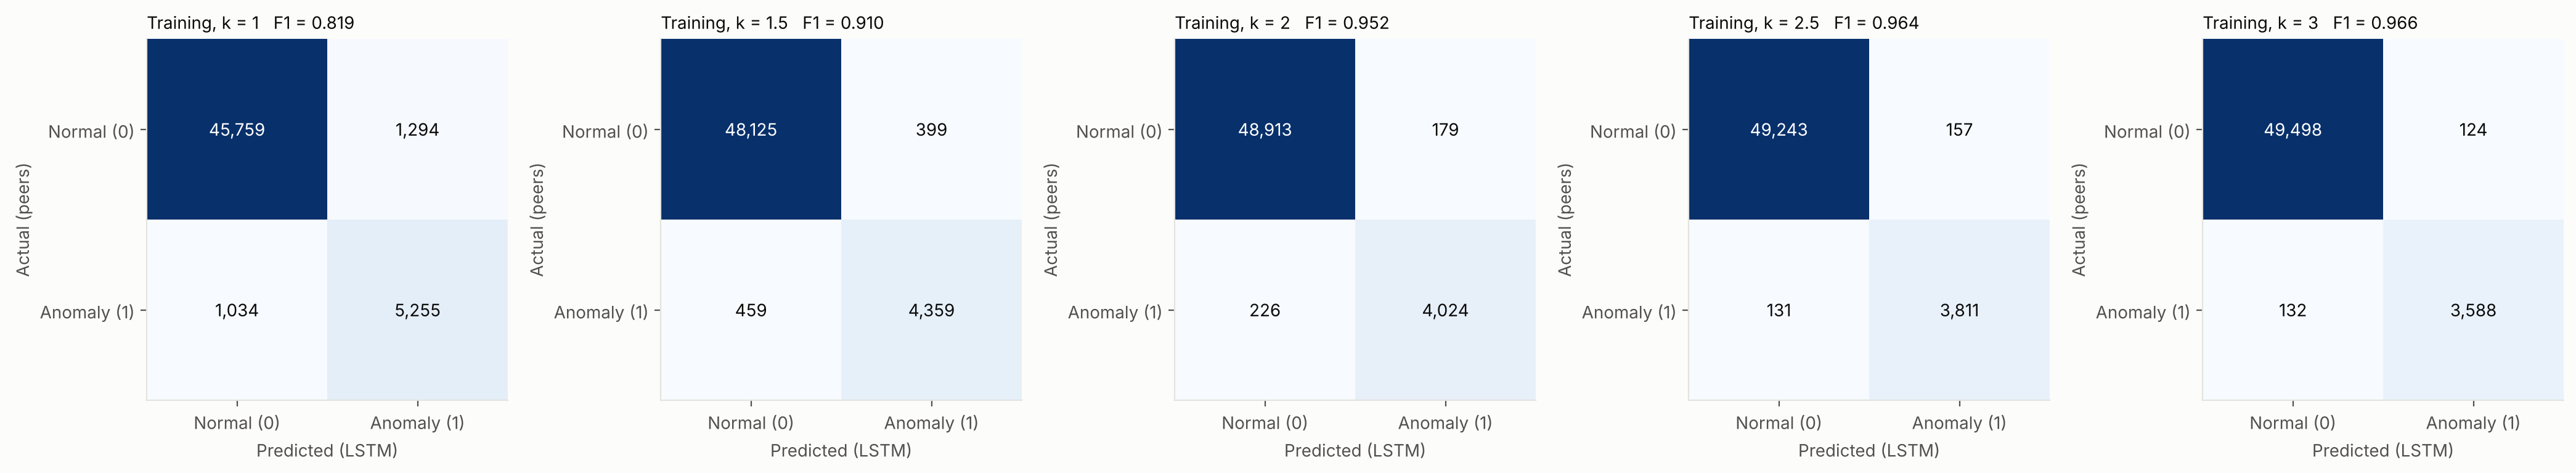

In [13]:
train_df = df[df.SPLIT == 'train']
fig, axes = plt.subplots(1, 5, figsize=(21, 4))
for ax, k in zip(axes, K_VALUES):
    f1 = table[(table.Split == 'Training') & (table.k == k)].F1.item()
    plot_cm(ax, train_df[f'actual_k{k:g}'], train_df[f'pred_k{k:g}'], f'Training, k = {k:g}   F1 = {f1:.3f}')
fig.tight_layout(); fig.savefig(RES / 'confusion_matrices_training.png', dpi=150); plt.show()

### Final result with the best k from training

,Split,k,TP,FP,FN,TN,Precision,Recall,F1
0,Training,3.0,3588,124,132,49498,0.9666,0.9645,0.9656
1,Validation,3.0,671,48,9,11240,0.9332,0.9868,0.9593
2,Testing,3.0,737,22,21,11012,0.9710,0.9723,0.9717


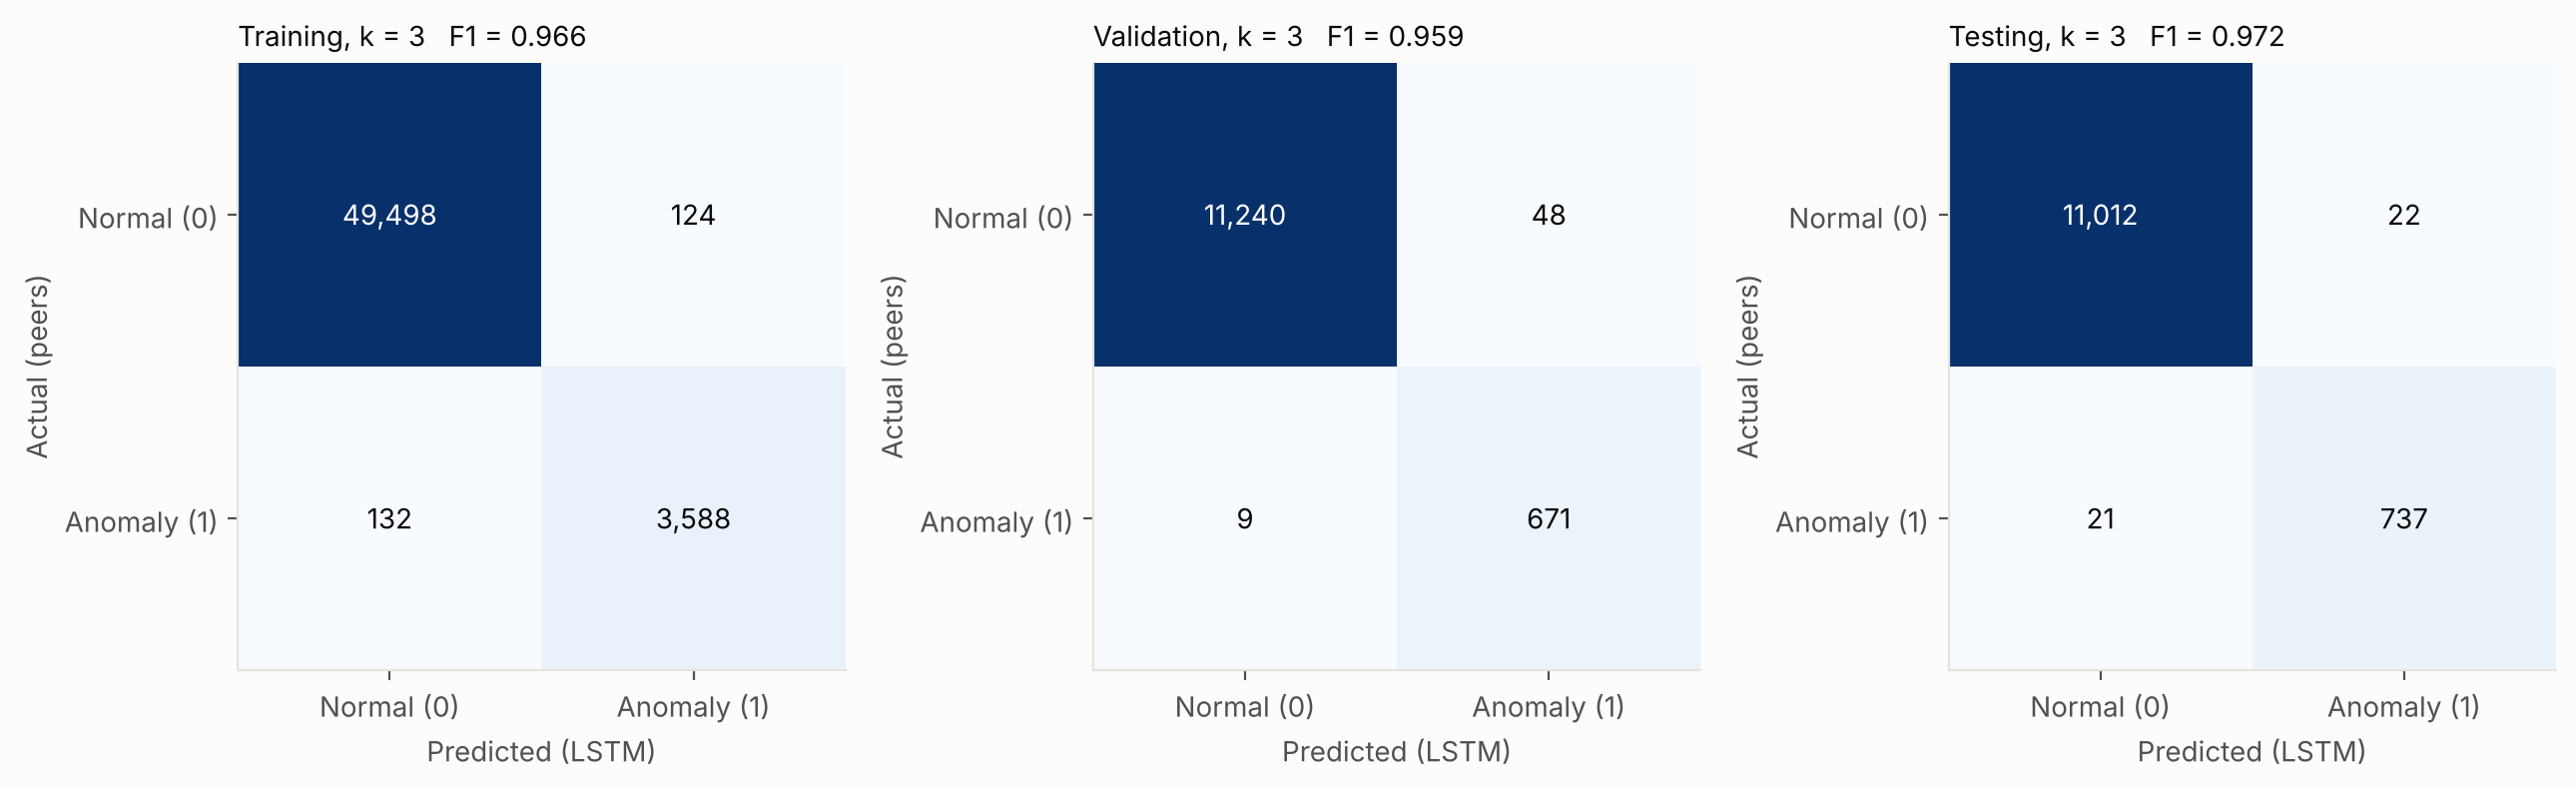

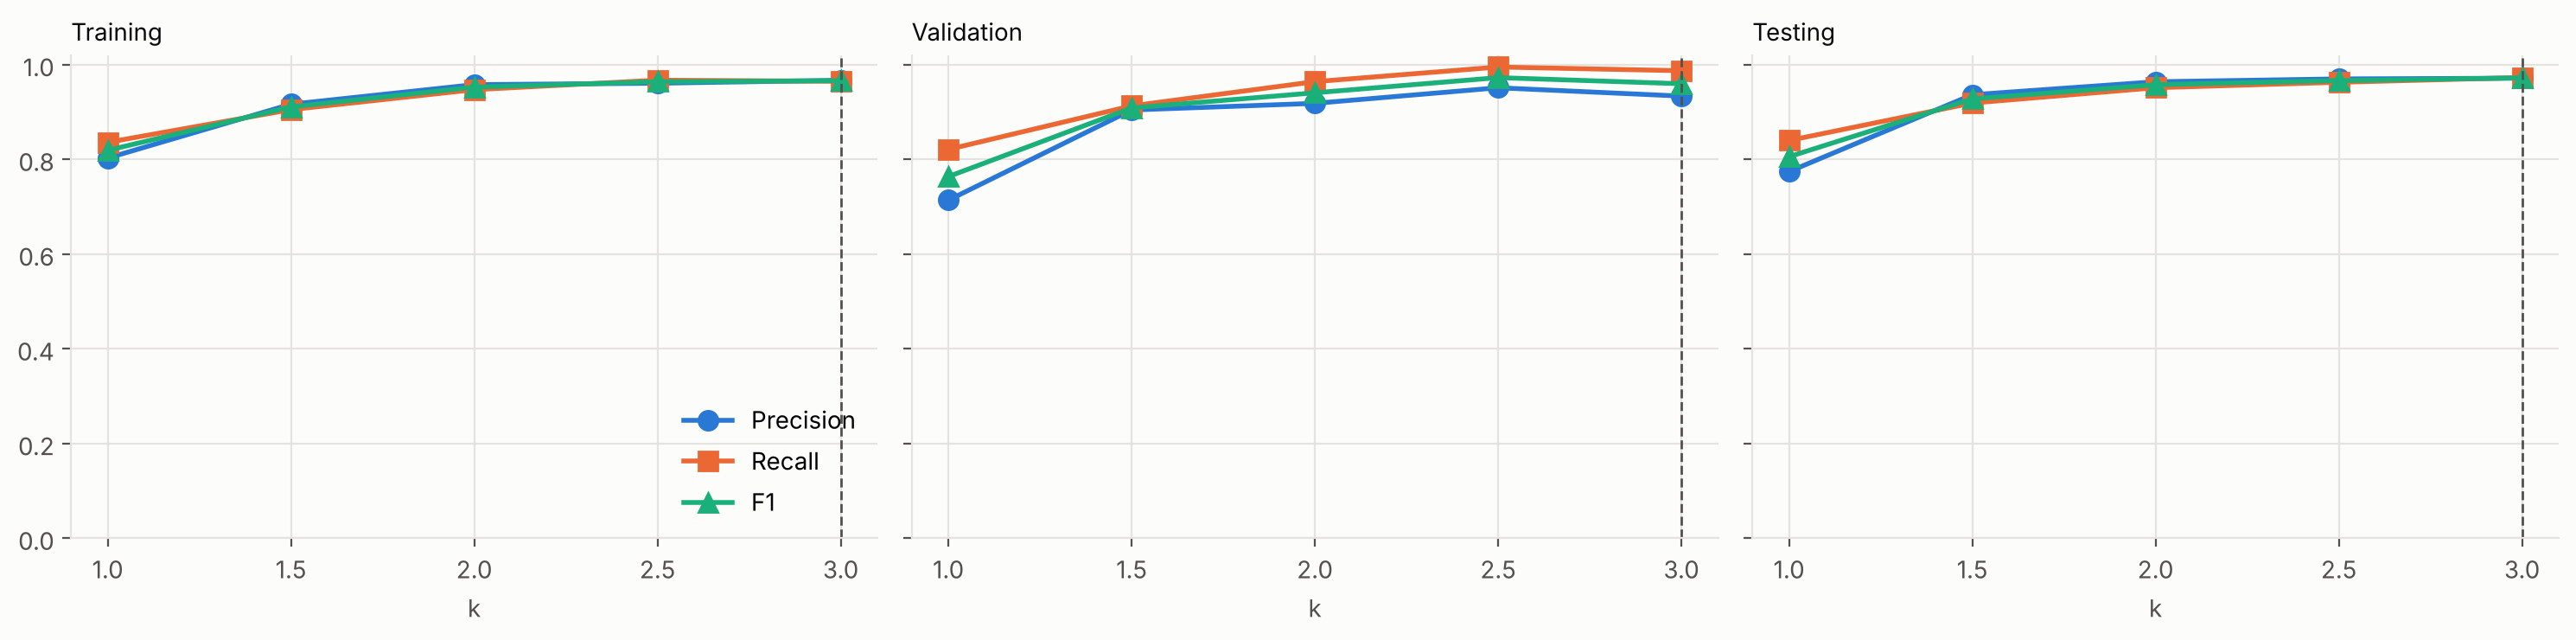

In [14]:
results = table[table.k == BEST_K].reset_index(drop=True)
results.to_csv(RES / 'results_best_k.csv', index=False)
display(results)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, s in zip(axes, SPLITS):
    g = df[df.SPLIT == s]
    plot_cm(ax, g[f'actual_k{BEST_K:g}'], g[f'pred_k{BEST_K:g}'],
            f'{SPLIT_NAMES[s]}, k = {BEST_K:g}   F1 = {results[results.Split == SPLIT_NAMES[s]].F1.item():.3f}')
fig.tight_layout(); fig.savefig(RES / 'confusion_matrices_best_k.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, s in zip(axes, SPLITS):
    m = table[table.Split == SPLIT_NAMES[s]]
    for col, color, mk in [('Precision', BLUE, 'o'), ('Recall', ORANGE, 's'), ('F1', AQUA, '^')]:
        ax.plot(m.k, m[col], marker=mk, markersize=8, color=color, label=col)
    ax.axvline(BEST_K, color=INK_2, linestyle='--', linewidth=1)
    ax.set_ylim(0, 1.02); ax.set_xticks(K_VALUES); ax.set_xlabel('k'); ax.set_title(SPLIT_NAMES[s], fontsize=10)
axes[0].legend(loc='lower right'); fig.tight_layout(); fig.savefig(RES / 'metrics_vs_k.png', dpi=150); plt.show()

In [15]:
def event_recall(g, a_col, p_col):
    found = total = 0
    for _, x in g.groupby('SOURCE_KEY'):
        a, p = x[a_col].to_numpy() != 0, x[p_col].to_numpy() != 0
        ev = np.cumsum(np.r_[True, a[1:] != a[:-1]])
        for e in np.unique(ev[a]):
            total += 1; found += bool(p[ev == e].any())
    return found, total

per_plant = sweep(df, 'actual', 'pred', by='PLANT_ID').query('k == @BEST_K').reset_index(drop=True)
per_plant.to_csv(RES / 'results_best_k_per_plant.csv', index=False)
display(per_plant)
for s in SPLITS:
    found, total = event_recall(df[df.SPLIT == s], f'actual_k{BEST_K:g}', f'pred_k{BEST_K:g}')
    print(f'{SPLIT_NAMES[s]:10s}: fault events found {found} of {total}')

,PLANT_ID,Split,k,TP,FP,FN,TN,Precision,Recall,F1
0,4135001,Training,3.0,58,8,1,26741,0.8788,0.9831,0.9280
1,4135001,Validation,3.0,1,0,1,5784,1.0000,0.5000,0.6667
2,4135001,Testing,3.0,33,0,1,5752,1.0000,0.9706,0.9851
3,4136001,Training,3.0,3530,116,131,22757,0.9682,0.9642,0.9662
4,4136001,Validation,3.0,670,48,8,5456,0.9331,0.9882,0.9599
5,4136001,Testing,3.0,704,22,20,5260,0.9697,0.9724,0.9710


Training  : fault events found 371 of 413
Validation: fault events found 104 of 104
Testing   : fault events found 105 of 109


### The 6 result files (same names as before)

In [16]:
ID = ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']
d = df.rename(columns={'AC_POWER': 'ACTUAL_AC_POWER_kW', 'EXPECTED_LSTM_kW': 'PREDICTED_AC_POWER_kW',
                       'EXPECTED_PEER_kW': 'EXPECTED_HEALTHY_PEERS_kW'})
KW = ['ACTUAL_AC_POWER_kW', 'PREDICTED_AC_POWER_kW']
for k in K_VALUES:
    d[f'actual_anomaly_k{k:g}'] = (d[f'actual_k{k:g}'] != 0).astype(int)
    d[f'predicted_anomaly_k{k:g}'] = (d[f'pred_k{k:g}'] != 0).astype(int)
ALL_K = [f'{line}_anomaly_k{k:g}' for line in ('actual', 'predicted') for k in K_VALUES]

def with_best_k(g, keep_kw=False):
    out = g[ID + (KW + ['EXPECTED_HEALTHY_PEERS_kW'] if keep_kw else [])].copy()
    out['K'] = BEST_K
    out['ACTUAL_ANOMALY'], out['PREDICTED_ANOMALY'] = g[f'actual_anomaly_k{BEST_K:g}'], g[f'predicted_anomaly_k{BEST_K:g}']
    out['ACTUAL_DIRECTION'], out['PREDICTED_DIRECTION'] = g[f'actual_k{BEST_K:g}'], g[f'pred_k{BEST_K:g}']
    a, p = out.ACTUAL_ANOMALY == 1, out.PREDICTED_ANOMALY == 1
    out['RESULT'] = np.select([a & p, ~a & p, a & ~p], ['TP', 'FP', 'FN'], default='TN')
    return out

sp = {s: d[d.SPLIT == s] for s in SPLITS}
final_files = {'1_LSTM_Training_Output_Prediction.csv': sp['train'][ID + KW],
               '2_LSTM_Training_Output_Thresholding.csv': sp['train'][ID + ALL_K],
               '3_LSTM_Validation_Output_Prediction.csv': sp['val'][ID + KW],
               '4_LSTM_Validation_Output_Thresholding.csv': with_best_k(sp['val']),
               '5_LSTM_Testing_Output_Prediction.csv': sp['test'][ID + KW],
               '6_LSTM_Testing_Output_Anomaly.csv': with_best_k(sp['test'], keep_kw=True)}
for name, f in final_files.items():
    f.to_csv(FINAL / name, index=False)
    print(f'{name:45s} {len(f):7,} rows')
counts = final_files['6_LSTM_Testing_Output_Anomaly.csv'].RESULT.value_counts()
assert all(counts.get(c, 0) == results[results.Split == 'Testing'][c].item() for c in ['TP', 'FP', 'FN', 'TN'])

1_LSTM_Training_Output_Prediction.csv          53,342 rows
2_LSTM_Training_Output_Thresholding.csv        53,342 rows
3_LSTM_Validation_Output_Prediction.csv        11,968 rows
4_LSTM_Validation_Output_Thresholding.csv      11,968 rows


5_LSTM_Testing_Output_Prediction.csv           11,792 rows
6_LSTM_Testing_Output_Anomaly.csv              11,792 rows


# Part 5 — Comparison with the previous method
Same ground truth for every detector, best k chosen on training each time, one change at a time.

,Detector,best k,Training F1,Validation F1,Testing F1,Testing precision,Testing recall
0,A. Previous definition (LSTM line alone),1.0,0.2067,0.2800,0.3241,0.2298,0.5494
1,"B. Residual in kW, mean ± k·std",1.5,0.5624,0.5824,0.5777,0.6400,0.5265
2,"C. Relative residual, robust σ",3.0,0.7181,0.7348,0.7618,0.6634,0.8945
3,D. C + 1-hour smoothing,3.0,0.8213,0.8064,0.8412,0.7281,0.9960
4,E. Final (D + σ minimum 10 %),3.0,0.9656,0.9593,0.9717,0.9710,0.9723
5,"F. Final rule, LSTM trained on all readings",3.0,0.6429,0.6620,0.6587,0.5433,0.8364
6,"G. Final rule, physical formula instead of LSTM",2.5,0.9558,0.9587,0.9600,0.9750,0.9455


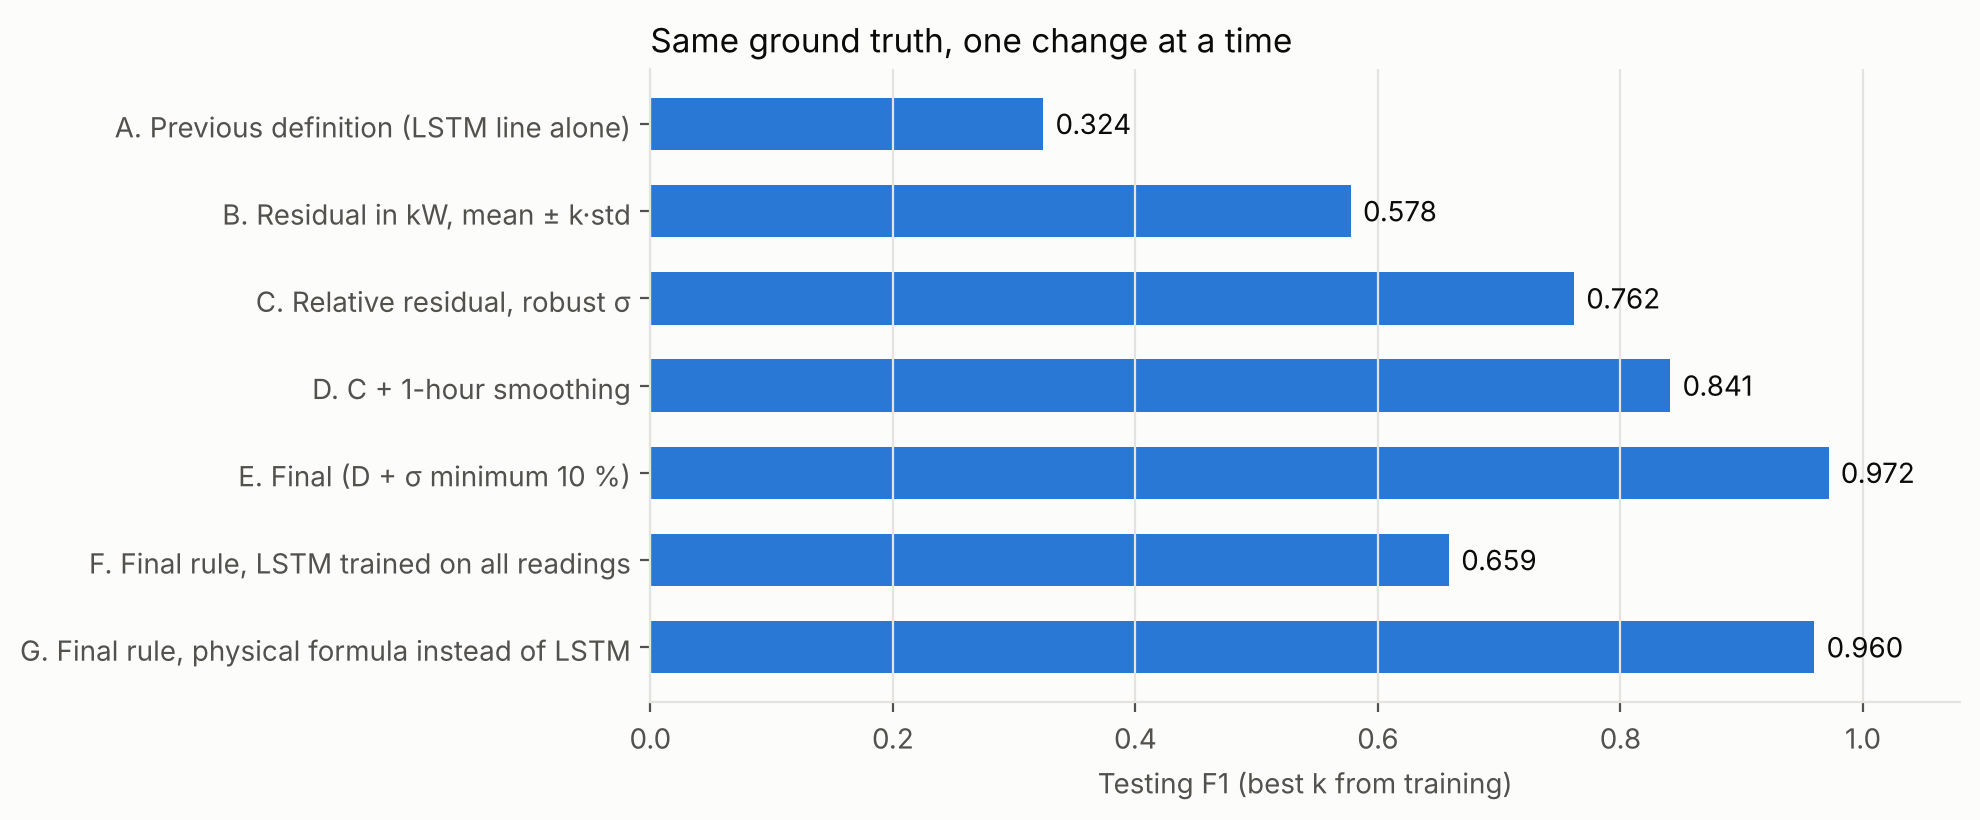

In [17]:
def previous_definition(series, k, min_history=10):
    """Previous rule: change from the previous reading outside mean ± k·std of the earlier changes, one line alone."""
    x = pd.Series(series).diff().fillna(0).to_numpy(); out = np.zeros(len(x), int)
    for t in range(min_history, len(x)):
        m, s = x[:t].mean(), x[:t].std()
        out[t] = int(x[t] != m) if s == 0 else int(abs(x[t] - m) > k * s)
    return out

if RUN_COMPARISON:
    all_targets = df.groupby(['PLANT_ID', 'DATE_TIME', 'SPLIT']).AC_POWER.agg(TARGET_kW='mean', N='size').reset_index()
    models_all = {p: [train(plant_data(all_targets, p, BEST_W), BEST_W, SEED + s)[0] for s in range(N_SEEDS)] for p in PLANTS}
    cmp = df[['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', 'SPLIT'] + [f'actual_k{k:g}' for k in K_VALUES]
             + [f'pred_k{k:g}' for k in K_VALUES]].copy()
    cmp['RES_KW'] = df.AC_POWER - df.EXPECTED_LSTM_kW
    cmp['DEV_LSTM'] = df.DEV_LSTM
    cmp['DEV_ALL'] = relative_deviation(df.AC_POWER, predict(models_all, BEST_W), df.FLOOR_kW)
    cmp['DEV_PHYS'] = relative_deviation(df.AC_POWER, df.EXPECTED_PHYS_kW, df.FLOOR_kW)
    for k in K_VALUES:
        cmp[f'A_k{k:g}'] = df.groupby('SOURCE_KEY').EXPECTED_LSTM_kW.transform(lambda s: previous_definition(s.to_numpy(), k))
    cmp = (cmp.join(flag_line(cmp, 'RES_KW', 'B', span=1, sigma_min=0, robust=False))
              .join(flag_line(cmp, 'DEV_LSTM', 'C', span=1, sigma_min=0))
              .join(flag_line(cmp, 'DEV_LSTM', 'D', sigma_min=0))
              .join(flag_line(cmp, 'DEV_ALL', 'F'))
              .join(flag_line(cmp, 'DEV_PHYS', 'G')))
    detectors = {'A. Previous definition (LSTM line alone)': 'A', 'B. Residual in kW, mean ± k·std': 'B',
                 'C. Relative residual, robust σ': 'C', 'D. C + 1-hour smoothing': 'D',
                 'E. Final (D + σ minimum 10 %)': 'pred', 'F. Final rule, LSTM trained on all readings': 'F',
                 'G. Final rule, physical formula instead of LSTM': 'G'}
    rows = []
    for name, pre in detectors.items():
        t = sweep(cmp, 'actual', pre); k = best_k(t); r = t[t.k == k].set_index('Split')
        rows.append({'Detector': name, 'best k': k, 'Training F1': r.loc['Training', 'F1'],
                     'Validation F1': r.loc['Validation', 'F1'], 'Testing F1': r.loc['Testing', 'F1'],
                     'Testing precision': r.loc['Testing', 'Precision'], 'Testing recall': r.loc['Testing', 'Recall']})
    comparison = pd.DataFrame(rows)
    comparison.to_csv(RES / 'comparison_with_previous.csv', index=False)
    display(comparison)

    fig, ax = plt.subplots(figsize=(10, 4.2))
    y = np.arange(len(comparison))[::-1]
    ax.barh(y, comparison['Testing F1'], color=BLUE, height=0.6)
    for yi, v in zip(y, comparison['Testing F1']):
        ax.text(v + 0.01, yi, f'{v:.3f}', va='center', color=INK)
    ax.set_yticks(y, comparison.Detector); ax.set_xlim(0, 1.08); ax.grid(axis='y', visible=False)
    ax.set_xlabel('Testing F1 (best k from training)'); ax.set_title('Same ground truth, one change at a time')
    fig.tight_layout(); fig.savefig(RES / 'comparison_with_previous.png', dpi=150); plt.show()

### How much of the real faults did the previous ground truth contain?

In [18]:
if RUN_COMPARISON:
    rows = []
    for k in K_VALUES:
        old = df.groupby('SOURCE_KEY').AC_POWER.transform(lambda s: previous_definition(s.to_numpy(), k)) != 0
        new = df[f'actual_k{k:g}'] != 0
        outage = (df[f'actual_k{k:g}'] == -1) & (df.AC_POWER == 0)
        rows.append({'k': k, 'new ground truth': int(new.sum()), 'also in previous': int((new & old).sum()),
                     'outage readings': int(outage.sum()), 'outages in previous': int((outage & old).sum()),
                     'share of outages in previous': round((outage & old).sum() / outage.sum(), 3)})
    previous_gt = pd.DataFrame(rows)
    previous_gt.to_csv(RES / 'previous_ground_truth_coverage.csv', index=False)
    display(previous_gt)

,k,new ground truth,also in previous,outage readings,outages in previous,share of outages in previous
0,1.0,8811,2854,3838,453,0.118
1,1.5,6776,1731,3826,376,0.098
2,2.0,5967,1229,3820,322,0.084
3,2.5,5506,870,3797,267,0.070
4,3.0,5158,593,3770,228,0.060


### Sensitivity of the smoothing span and the σ minimum (training and validation only)
A larger σ minimum always raises F1 because it keeps only the largest anomalies, so it is fixed at 10 % and
not chosen by F1. The last column shows what a larger value costs: big losses dropped from the ground truth.

In [19]:
if RUN_COMPARISON:
    big = (df.AC_POWER < 0.5 * df.EXPECTED_PEER_kW) & (df.EXPECTED_PEER_kW > 0.1 * df.CAPACITY_kW)
    rows = []
    for span in [1, 2, 4, 6]:
        for smin in [0.05, 0.075, 0.10, 0.125, 0.15]:
            t = df[['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', 'SPLIT']].join(flag_line(df, 'DEV_PEER', 'a', span, smin)) \
                .join(flag_line(df, 'DEV_LSTM', 'p', span, smin))
            tab = sweep(t, 'a', 'p'); k = best_k(tab); r = tab[tab.k == k].set_index('Split')
            rows.append({'EWMA span': span, 'σ minimum': smin, 'best k': k, 'Training F1': r.loc['Training', 'F1'],
                         'Validation F1': r.loc['Validation', 'F1'],
                         'big losses kept': round((big & (t[f'a_k{k:g}'] != 0)).sum() / big.sum(), 3)})
    sensitivity = pd.DataFrame(rows)
    sensitivity.to_csv(RES / 'sensitivity_span_sigma_min.csv', index=False)
    display(sensitivity.pivot(index='EWMA span', columns='σ minimum', values='Validation F1'))

σ minimum,0.050,0.075,0.100,0.125,0.150
EWMA span,,,,,
1,0.7962,0.8869,0.9199,0.9390,0.9723
2,0.8388,0.9106,0.9633,0.9786,0.9722
4,0.9072,0.9636,0.9593,0.9458,0.9664
6,0.9204,0.9434,0.9349,0.9666,0.9669


## Save and download

In [20]:
shutil.make_archive(str(RES / 'final_files'), 'zip', FINAL)
with open(RES / 'summary.json', 'w') as f:
    json.dump({'best_window': BEST_W, 'best_k': BEST_K,
               'f1': results.set_index('Split').F1.to_dict()}, f, indent=2)
zip_path = shutil.make_archive(str(OUT / 'SUNSHIELD_results'), 'zip', RES)
print('saved:', sorted(p.name for p in RES.iterdir()))
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

saved: ['comparison_with_previous.csv', 'comparison_with_previous.png', 'confusion_matrices_best_k.png', 'confusion_matrices_training.png', 'definition_example_outage.png', 'f1_all_k.csv', 'final_files.zip', 'metrics_vs_k.png', 'previous_ground_truth_coverage.csv', 'results_best_k.csv', 'results_best_k_per_plant.csv', 'sensitivity_span_sigma_min.csv', 'summary.json']
